Data Cleaning

In [2]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../dataset/retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 9)


In [4]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


Check Missing Values

In [6]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [7]:
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 0


In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing value percentage:")
print(missing_percentage)

Missing value percentage:
Transaction ID      0.0
Date                0.0
Customer ID         0.0
Gender              0.0
Age                 0.0
Product Category    0.0
Quantity            0.0
Price per Unit      0.0
Total Amount        0.0
dtype: float64


### Observation — Missing Values

The dataset was checked for missing values across all columns. No missing
values were identified, indicating that the dataset is complete with respect
to null entries. Therefore, no missing-value imputation or row removal is
required at this stage.

Detect Duplicate Records

In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [10]:
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))

Original rows: 1000
Rows after removing duplicates: 1000


In [11]:
print("Duplicates remaining:", df_clean.duplicated().sum())

Duplicates remaining: 0


### Observation — Duplicate Records

The dataset was checked for duplicate records. Duplicate rows were removed
using the pandas `drop_duplicates()` method. After cleaning, the dataset was
verified to ensure that no duplicate records remained.

Check and Correct Data Types

In [12]:
print("Data types before correction:")
print(df_clean.dtypes)

Data types before correction:
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object


In [13]:
df_clean["Date"] = pd.to_datetime(df_clean["Date"])

print("Data types after correction:")
print(df_clean.dtypes)

Data types after correction:
Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [14]:
print("Date data type:", df_clean["Date"].dtype)

Date data type: datetime64[us]


### Observation — Data Types

The data types of all columns were inspected and corrected where necessary.
The Date column was converted from object/string format to datetime format.
This ensures that date-based analysis and time-series operations can be
performed correctly.

Check Invalid or Inconsistent Values

In [15]:
print("Minimum values:")
print(df_clean[["Age", "Quantity", "Price per Unit", "Total Amount"]].min())

print("\nMaximum values:")
print(df_clean[["Age", "Quantity", "Price per Unit", "Total Amount"]].max())

Minimum values:
Age               18
Quantity           1
Price per Unit    25
Total Amount      25
dtype: int64

Maximum values:
Age                 64
Quantity             4
Price per Unit     500
Total Amount      2000
dtype: int64


In [16]:
print("Invalid Age values:", (df_clean["Age"] <= 0).sum())
print("Invalid Quantity values:", (df_clean["Quantity"] <= 0).sum())
print("Invalid Price values:", (df_clean["Price per Unit"] <= 0).sum())
print("Invalid Total Amount values:", (df_clean["Total Amount"] <= 0).sum())

Invalid Age values: 0
Invalid Quantity values: 0
Invalid Price values: 0
Invalid Total Amount values: 0


In [17]:
print("Gender values:")
print(df_clean["Gender"].unique())

print("\nProduct Category values:")
print(df_clean["Product Category"].unique())

Gender values:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Product Category values:
<StringArray>
['Beauty', 'Clothing', 'Electronics']
Length: 3, dtype: str


### Observation — Invalid and Inconsistent Values

The numerical columns were checked for invalid or non-positive values.
Categorical columns were also inspected for inconsistent categories.
The dataset was found to contain valid values suitable for further analysis.

Detect Outliers

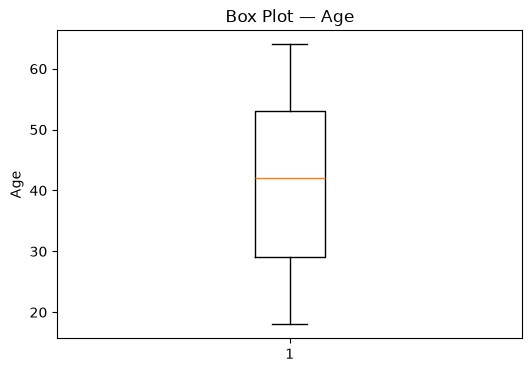

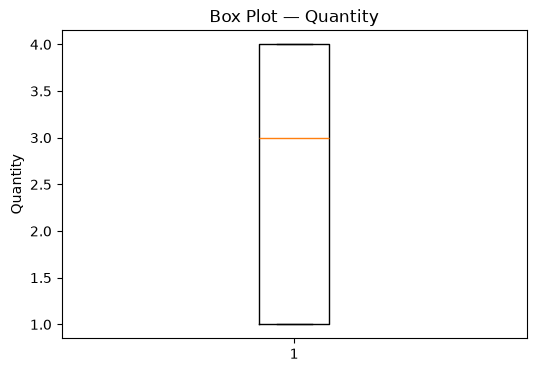

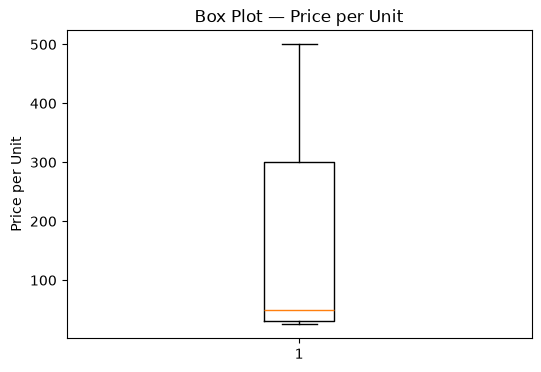

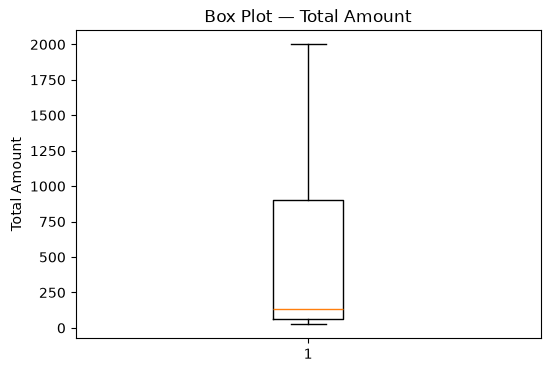

In [18]:
import matplotlib.pyplot as plt

numerical_columns = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

for column in numerical_columns:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df_clean[column])
    plt.title(f"Box Plot — {column}")
    plt.ylabel(column)
    plt.show()

In [19]:
for column in numerical_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_limit) |
        (df_clean[column] > upper_limit)
    ]

    print(f"{column}: {len(outliers)} outliers")

Age: 0 outliers
Quantity: 0 outliers
Price per Unit: 0 outliers
Total Amount: 0 outliers


### Observation — Outlier Detection

Box plots and the IQR method were used to identify potential outliers in the
numerical variables. Outliers were inspected before deciding whether any
records should be removed. Legitimate extreme values should be retained
because they may represent genuine customer transactions.

Standardize Text and Categorical Data

In [20]:
print("Gender values before cleaning:")
print(df_clean["Gender"].unique())

print("\nProduct Category values before cleaning:")
print(df_clean["Product Category"].unique())

Gender values before cleaning:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Product Category values before cleaning:
<StringArray>
['Beauty', 'Clothing', 'Electronics']
Length: 3, dtype: str


In [21]:
df_clean["Gender"] = df_clean["Gender"].str.strip()
df_clean["Product Category"] = df_clean["Product Category"].str.strip()

print("Text values standardized successfully.")

Text values standardized successfully.


In [22]:
print("Gender values after cleaning:")
print(df_clean["Gender"].unique())

print("\nProduct Category values after cleaning:")
print(df_clean["Product Category"].unique())

Gender values after cleaning:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Product Category values after cleaning:
<StringArray>
['Beauty', 'Clothing', 'Electronics']
Length: 3, dtype: str


### Observation — Categorical Data Standardization

Categorical text values were checked and standardized by removing unnecessary
leading and trailing spaces. This helps maintain consistency in categorical
values and prevents duplicate categories caused by formatting differences.

Final Data Quality Check

In [23]:
print("Missing values:")
print(df_clean.isnull().sum())

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [24]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [25]:
print("Data types:")
print(df_clean.dtypes)

Data types:
Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [26]:
print("Final dataset shape:", df_clean.shape)

Final dataset shape: (1000, 9)


In [27]:
print("========== FINAL DATA QUALITY CHECK ==========")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Total missing values:", df_clean.isnull().sum().sum())
print("Total duplicate rows:", df_clean.duplicated().sum())

========== FINAL DATA QUALITY CHECK ==========
Rows: 1000
Columns: 9
Total missing values: 0
Total duplicate rows: 0


### Observation — Final Data Quality Check

The cleaned dataset was verified for missing values, duplicate records, data
types, and overall dimensions. The final dataset is consistent and suitable
for further data analysis and visualization.

Cleaned Dataset

In [28]:
output_path = "../output/cleaned_retail_sales_dataset.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File:", output_path)

Cleaned dataset saved successfully!
File: ../output/cleaned_retail_sales_dataset.csv


In [29]:
import os

print("File exists:", os.path.exists(output_path))

File exists: True


## Final Conclusion

The retail sales dataset was successfully cleaned and prepared for analysis.
The cleaning process included checking missing values, removing duplicate
records, correcting data types, checking invalid values, detecting outliers,
and standardizing categorical data. The final cleaned dataset was saved as a
CSV file for future analysis.